# Stacked DiD

Stacked difference-in-differences (Wing, Freedman & Hollingsworth 2024) handles staggered
adoption by going back to the simplest design. For each adoption date it builds one
clean comparison, treated units against units that are not treated anywhere in a fixed
window around that date, then stacks those comparisons and runs a single weighted
regression. This tutorial asks **what goes into that stack, which choices you have to
make, and what the resulting number is an estimate of.**

**What you'll learn**

- How the stacked dataset is built, and how to inspect it
- What the overall estimate targets: an average over a fixed event window
- How the window trades pre- and post-treatment coverage against losing cohorts
- What the weighting schemes and the clean-control definitions change
- How it compares with Callaway-Sant'Anna and Imputation DiD

**Prerequisites:** [Staggered DiD](02_staggered_did.ipynb).

In [1]:
import numpy as np
import pandas as pd

from diff_diff import (
    CallawaySantAnna,
    ImputationDiD,
    StackedDiD,
    generate_staggered_data,
    plot_event_study,
)

## What it estimates and assumes

The estimator has four steps:

1. **Split** the data into sub-experiments, one per adoption cohort. Each holds that
   cohort's treated units and a set of *clean controls*.
2. **Restrict** each sub-experiment to an event window: `kappa_pre` periods before
   adoption to `kappa_post` periods after. A unit enters a sub-experiment only if it is
   observed at every period of that window; on a panel with missing observations `fit()`
   warns with the counts.
3. **Weight.** Stacking gives cohorts with more controls more influence than they should
   have. Corrective weights (Q-weights) undo that.
4. **Regress.** One weighted event-study regression on the stacked data.

**Target parameter.** The *trimmed aggregate ATT*: the average effect on treated units
over event times 0 to `kappa_post`, across the cohorts whose whole window fits in the
data, weighted by cohort size. Two things follow. The target depends on the window you
choose, and a cohort that does not fit is left out of it. If effects change with time
since treatment, a longer `kappa_post` is a different target, not a better estimate of
the same one.

**Identifying assumptions.**

- **Parallel trends within each sub-experiment:** without treatment, the cohort and its
  clean controls would have moved in parallel over the event window.
- **No anticipation** before adoption (or only within the periods declared with
  `anticipation`).
- Treatment is **absorbing**.

**What would violate it.** Controls that are on a different path from the cohort they
are compared with, or that start treatment inside the window. The second is what the
clean-control rule is there to prevent.

## Simulated data

A panel of 300 units over 10 periods (0 to 9). Cohorts start treatment in periods 3, 5
and 7, and 90 units are never treated. The true effect is 2.0 for every treated unit in
every treated period, so every window targets the same number.

In [2]:
TRUE_ATT = 2.0

data = generate_staggered_data(
    n_units=300,
    n_periods=10,
    treatment_effect=TRUE_ATT,
    dynamic_effects=False,  # constant effect: the same in every period after treatment
    seed=42,
)
fit_args = dict(outcome="outcome", unit="unit", time="period", first_treat="first_treat")

cohort_sizes = data.groupby("unit")["first_treat"].first().value_counts().sort_index()
print("Units by first treated period (0 = never treated):")
print(cohort_sizes.to_string())
print(f"\nTrue ATT: {TRUE_ATT}")

Units by first treated period (0 = never treated):
first_treat
0    90
3    60
5    75
7    75

True ATT: 2.0


## Fitting the estimator

The one choice you cannot avoid is the event window. Start with two periods on each
side. Standard errors are clustered by unit, the default.

In [3]:
results = StackedDiD(kappa_pre=2, kappa_post=2).fit(data, **fit_args)

print(results.summary())

         Stacked DiD Estimator Results (Wing, Freedman & Hollingsworth 2024)         

Original observations:               3000
Stacked observations:                2775
Sub-experiments:                        3
Treated units:                        210
Control units:                        165
Treatment cohorts:                      3
Trimmed cohorts:                        0
Event window:                     [-2, 2]
Weighting:                      aggregate
Control group:                 not_yet_treated

Variance:                                       CR1 cluster-robust at unit, G=300

-------------------------------------------------------------------------------------
                   Overall Average Treatment Effect on the Treated                   
-------------------------------------------------------------------------------------
Parameter           Estimate    Std. Err.     t-stat      P>|t|   Sig.
---------------------------------------------------------------------------

In [4]:
print(f"Estimate: {results.att:.3f}  (SE {results.se:.3f})")
print(f"95% CI:   [{results.conf_int[0]:.3f}, {results.conf_int[1]:.3f}]")
print(f"True ATT: {TRUE_ATT:.3f}")

Estimate: 1.922  (SE 0.051)
95% CI:   [1.822, 2.022]
True ATT: 2.000


The estimate is 1.92 with a 95% interval of [1.82, 2.02]. The interval contains the true
effect of 2.0, towards its upper end.

"Control units: 165" is the 90 never-treated units plus the 75 units of the last cohort,
which adopt in period 7 and so are clean controls for the cohort that adopts in period 3
(its window closes in period 5).

## Event study

The regression estimates one coefficient per event time in the window, with the period
before adoption (event time -1) as the reference.

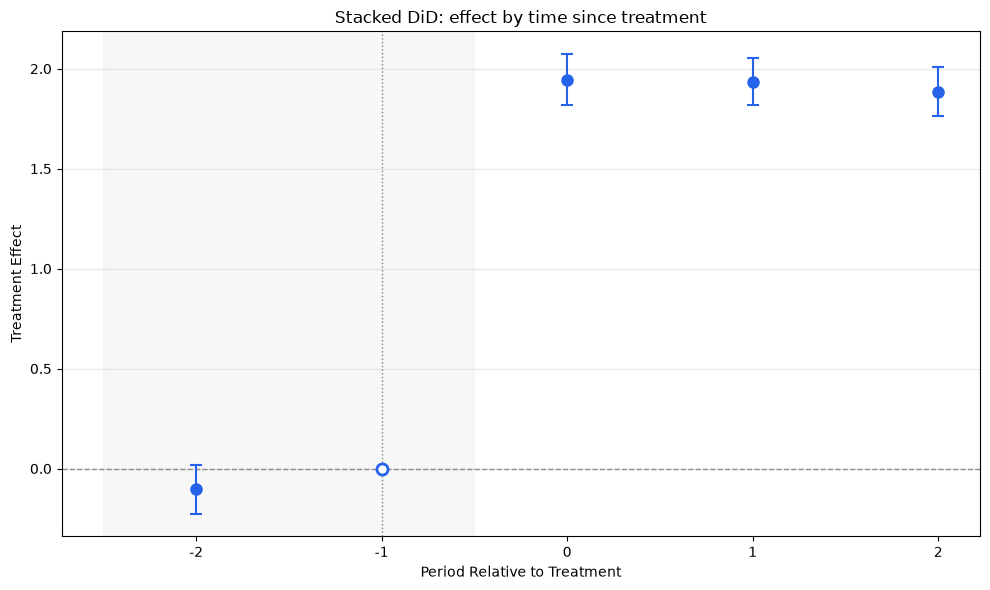

In [5]:
es = results.aggregate("event_study")

ax = plot_event_study(es, title="Stacked DiD: effect by time since treatment", show=False)

In [6]:
columns = ["event_time", "att", "se", "conf_int_lower", "conf_int_upper", "is_reference"]
print(es.to_dataframe()[columns].round(3).to_string(index=False))

 event_time    att    se  conf_int_lower  conf_int_upper  is_reference
         -2 -0.103 0.062          -0.225           0.019         False
         -1  0.000   NaN             NaN             NaN          True
          0  1.945 0.065           1.817           2.072         False
          1  1.936 0.059           1.821           2.051         False
          2  1.885 0.063           1.762           2.009         False


The three post-treatment estimates are between 1.89 and 1.95, and each interval contains
2.0. With `kappa_pre=2` there is a single pre-treatment coefficient, -0.10 with an
interval that includes zero. One coefficient is very little to judge pre-treatment
behaviour by; a longer `kappa_pre` gives more, at the cost discussed below. And as in
every event study, a pre-treatment coefficient near zero is not confirmation of parallel
trends; see [Pre-Trends Power](07_pretrends_power.ipynb).

Every coefficient is measured against the same reference period, so noise in that one
period moves all of them together. That is consistent with what the table shows: the
pre-treatment coefficient is about 0.1 below zero and the post-treatment ones about 0.1
below 2.0.

## Inside the stacked dataset

The stacked data is available as `results.stacked_data`, so you can check exactly which
comparisons the estimate is built from. It has the original columns plus four:

- `_sub_exp`: the adoption cohort that defines the sub-experiment
- `_event_time`: time relative to that cohort's adoption
- `_D_sa`: 1 for the cohort's treated units, 0 for its clean controls
- `_Q_weight`: the corrective weight

In [7]:
stacked = results.stacked_data

print(f"Original rows: {len(data)}")
print(f"Stacked rows:  {len(stacked)}")
print()
print(f"{'Sub-experiment':>15} {'Rows':>6} {'Treated units':>14} {'Control units':>14} {'Control Q-weight':>17}")
for cohort, sub in stacked.groupby("_sub_exp"):
    treated = sub[sub["_D_sa"] == 1]
    controls = sub[sub["_D_sa"] == 0]
    print(
        f"{int(cohort):>15} {len(sub):>6} {treated['unit'].nunique():>14} "
        f"{controls['unit'].nunique():>14} {controls['_Q_weight'].mean():>17.3f}"
    )
print()
print(f"Q-weight of treated observations: {stacked.loc[stacked['_D_sa'] == 1, '_Q_weight'].unique()}")

Original rows: 3000
Stacked rows:  2775

 Sub-experiment   Rows  Treated units  Control units  Control Q-weight
              3   1125             60            165             0.597
              5    825             75             90             1.369
              7    825             75             90             1.369

Q-weight of treated observations: [1.]


Each sub-experiment has five periods per unit, so the sub-experiment for cohort 3 has
(60 + 165) x 5 = 1,125 rows. The stack is smaller than the original data because periods
outside the windows are dropped, even though control units appear more than once.

The Q-weights explain themselves here. Cohort 3 supplies 60 of the 210 treated units
(29%) but its sub-experiment holds 165 of the 345 control appearances (48%). Left alone,
its controls would dominate the comparison, so they are weighted by 0.29 / 0.48 = 0.60.
The other two sub-experiments are weighted up, by 1.37. Under this default weighting
scheme treated observations have weight 1.

## The event window and trimming

A cohort enters the stack only if its whole window `[a - kappa_pre, a + kappa_post]` fits
inside the observed periods, and it has at least one clean control. Cohorts that fail
are **trimmed**, and the estimator warns when that happens. The next cell widens the
window step by step; the warnings it prints are expected.

In [8]:
print(f"{'Window':>9} {'Cohorts kept':>14} {'Trimmed':>9} {'ATT':>7} {'SE':>7} {'95% CI':>18}")
for kappa_pre, kappa_post in [(1, 1), (2, 2), (3, 3), (4, 4)]:
    fit = StackedDiD(kappa_pre=kappa_pre, kappa_post=kappa_post).fit(data, **fit_args)
    kept = [int(g) for g in fit.groups]
    trimmed = [int(g) for g in fit.trimmed_groups]
    lower, upper = fit.conf_int
    print(
        f"{f'[-{kappa_pre}, {kappa_post}]':>9} {str(kept):>14} {str(trimmed):>9} "
        f"{fit.att:>7.3f} {fit.se:>7.3f} {f'[{lower:.3f}, {upper:.3f}]':>18}"
    )

   Window   Cohorts kept   Trimmed     ATT      SE             95% CI
  [-1, 1]      [3, 5, 7]        []   1.928   0.054     [1.821, 2.035]
  [-2, 2]      [3, 5, 7]        []   1.922   0.051     [1.822, 2.022]
  [-3, 3]         [3, 5]       [7]   2.005   0.061     [1.885, 2.125]
  [-4, 4]            [5]    [3, 7]   1.986   0.087     [1.815, 2.157]


<ipython-cell>.py:3: UserWarning: Trimmed 1 adoption event(s) that don't satisfy inclusion criteria: [np.float64(7.0)]. IC1 requires event window [-3, 3] to fit within data range [0, 9]. IC2 requires clean controls to exist.
  fit = StackedDiD(kappa_pre=kappa_pre, kappa_post=kappa_post).fit(data, **fit_args)
<ipython-cell>.py:3: UserWarning: Trimmed 2 adoption event(s) that don't satisfy inclusion criteria: [np.float64(3.0), np.float64(7.0)]. IC1 requires event window [-4, 4] to fit within data range [0, 9]. IC2 requires clean controls to exist.
  fit = StackedDiD(kappa_pre=kappa_pre, kappa_post=kappa_post).fit(data, **fit_args)


The warnings say which cohorts were dropped. With the window [-3, 3], cohort 7 would
need period 10, and the data ends at 9. With [-4, 4], cohort 3 would need period -1 as
well, so only cohort 5 is left.

The estimates move between 1.92 and 2.01 and every interval contains the true effect;
with a constant effect, every window targets the same number and the movement is
sampling noise. The standard error is the thing to watch: it rises from 0.05 to 0.09 as
cohorts are lost. With effects that change over time since treatment, a longer
`kappa_post` would also move the target itself.

When you see a trimming warning:

1. Check `results.trimmed_groups`. If the dropped cohorts matter for your question, the
   window is too wide.
2. Consider an asymmetric window. `kappa_pre` and `kappa_post` need not be equal. Cohort
   7 was dropped from [-3, 3] on the post-treatment side only, so keeping three
   pre-treatment periods and two post-treatment ones brings it back:

In [9]:
asymmetric = StackedDiD(kappa_pre=3, kappa_post=2).fit(data, **fit_args)

print(f"Window [-3, 2]: cohorts kept {[int(g) for g in asymmetric.groups]}, trimmed {[int(g) for g in asymmetric.trimmed_groups]}")
print(f"ATT = {asymmetric.att:.3f}  (SE {asymmetric.se:.3f})")

Window [-3, 2]: cohorts kept [3, 5, 7], trimmed []
ATT = 1.922  (SE 0.051)


All three cohorts are kept and there is no warning. The overall estimate is the same as
for [-2, 2]. That is not automatic. Both fits average event times 0 to 2, and on this
panel they also use the same treated units, the same clean controls and weights, and
the same reference period, so the post-treatment estimates are identical. A longer
`kappa_pre` can change those: it can trim a cohort, and under `control_group="strict"`
it moves the clean-control cutoff. Here it only adds a second pre-treatment coefficient
to the event study.

## Weighting schemes

The Q-weights determine how the cohorts are averaged, and so which population the
estimate describes. Wing et al. define three:

- **`"aggregate"`** (default): each cohort counts in proportion to its number of treated
  units. This is the trimmed aggregate ATT.
- **`"population"`**: each cohort counts in proportion to the population its treated
  units stand for. You name a column with `population=` that holds a population for each
  unit; a cohort's weight is the sum over its treated units.
- **`"sample_share"`**: each cohort counts in proportion to its sub-experiment's share of
  the stacked sample.

Under the two alternative schemes the treated observations are reweighted as well as the
controls, so that both arms are averaged over cohorts in the same proportions.

In [10]:
with_population = data.copy()
cohort_population = {3: 1000, 5: 2000, 7: 500}  # the population each unit of the cohort stands for
with_population["population"] = with_population["first_treat"].map(cohort_population).fillna(0).astype(int)

print(f"{'Weighting':<14} {'ATT':>7} {'SE':>7}")
for scheme in ["aggregate", "population", "sample_share"]:
    extra = {"population": "population"} if scheme == "population" else {}
    fit = StackedDiD(kappa_pre=2, kappa_post=2, weighting=scheme).fit(with_population, **fit_args, **extra)
    print(f"{scheme:<14} {fit.att:>7.3f} {fit.se:>7.3f}")

Weighting          ATT      SE
aggregate        1.922   0.051
population       1.960   0.058
sample_share     1.939   0.051


The population column gives each unit of cohort 3 a population of 1,000, each unit of
cohort 5 2,000 and each unit of cohort 7 500. With 60, 75 and 75 treated units, the
cohorts stand for 60,000, 150,000 and 37,500 people, so they enter with weights of 24%,
61% and 15%, against 29%, 36% and 36% under the default.

The three estimates are close because the true effect is the same for every cohort, so
every weighted average of cohort effects is 2.0 and the differences are sampling noise
averaged in different proportions. With effects that differ by cohort they would be
estimates of different quantities. Choose the scheme by the population you want the
number to describe, not by which gives the smallest standard error.

## Clean-control definitions

`control_group` sets which units may serve as controls in the sub-experiment for a cohort
adopting at `a`:

- **`"not_yet_treated"`** (default): never-treated units, and units that adopt after the
  window closes (after `a + kappa_post`).
- **`"strict"`**: never-treated units, and units that adopt after `a + kappa_post +
  kappa_pre`, so that their own pre-treatment window does not overlap this one.
- **`"never_treated"`**: never-treated units only.

With `anticipation=k`, both cutoffs for later adopters move out by `k` periods: a unit
that starts responding `k` periods before its own adoption is a clean control only if
that response begins after this window has closed.

These are different comparisons, each needing parallel trends for the controls it uses.
None is uniformly the safer choice: admitting later adopters adds data and an
assumption about them; restricting to never-treated units rests everything on that one
group being comparable.

In [11]:
print(f"{'Controls':<17} {'ATT':>7} {'SE':>7} {'Control units':>14} {'95% CI':>18}")
for definition in ["not_yet_treated", "strict", "never_treated"]:
    fit = StackedDiD(kappa_pre=2, kappa_post=2, control_group=definition).fit(data, **fit_args)
    lower, upper = fit.conf_int
    print(
        f"{definition:<17} {fit.att:>7.3f} {fit.se:>7.3f} {fit.n_control_units:>14} "
        f"{f'[{lower:.3f}, {upper:.3f}]':>18}"
    )

Controls              ATT      SE  Control units             95% CI
not_yet_treated     1.922   0.051            165     [1.822, 2.022]
strict              1.937   0.051             90     [1.836, 2.037]
never_treated       1.937   0.051             90     [1.836, 2.037]


`"strict"` and `"never_treated"` give the same result here. Under the strict rule a
later adopter must start treatment after `a + 4`; for cohort 3 that means after period
7, and the last cohort adopts *in* period 7, so no later adopter qualifies for any
cohort and only the 90 never-treated units remain. The default uses 165 control units.
All three intervals contain the true effect, and the standard errors are almost equal:
in this design the choice barely matters. In real data it can, and a material gap
between the definitions is a reason to look at the later adopters' pre-treatment paths.

## Comparison with other estimators

Callaway-Sant'Anna and Imputation DiD average over every treated period in the data.
Stacked DiD averages over the event window only. With a constant effect, as here, those
targets coincide at 2.0, so the three estimates should agree up to sampling error.

In [12]:
fits = {
    "StackedDiD [-2, 2]": results,
    "CallawaySantAnna": CallawaySantAnna().fit(data, **fit_args),
    "ImputationDiD": ImputationDiD().fit(data, **fit_args),
}

print(f"{'Estimator':<20} {'ATT':>7} {'SE':>8} {'95% CI':>18} {'covers 2.0':>11}")
for name, fit in fits.items():
    lower, upper = fit.conf_int
    print(
        f"{name:<20} {fit.att:>7.3f} {fit.se:>8.4f} {f'[{lower:.3f}, {upper:.3f}]':>18} "
        f"{str(lower <= TRUE_ATT <= upper):>11}"
    )

Estimator                ATT       SE             95% CI  covers 2.0
StackedDiD [-2, 2]     1.922   0.0509     [1.822, 2.022]        True
CallawaySantAnna       1.975   0.0528     [1.872, 2.079]        True
ImputationDiD          1.982   0.0369     [1.909, 2.054]        True


All three intervals contain 2.0. Stacked DiD and Callaway-Sant'Anna have similar
standard errors; Imputation DiD's is smaller because it uses every untreated
observation, where the stack uses five periods per cohort.

This agreement depends on the constant effect. If effects grew with time since
treatment, Stacked DiD with `kappa_post=2` would report the average over the first three
treated periods and the other two the average over all of them. The estimates would then
differ because the questions differ, and the gap would not be evidence against any of
them.

## Options

### Anticipation

`anticipation=k` moves the reference period `k` periods earlier, to event time `-1 - k`,
and counts the periods from `-k` onward as treated. The event window grows by the same
`k` periods at the front, to `[-kappa_pre - k, kappa_post]`, so a cohort whose longer
window no longer fits in the data is trimmed and the set of cohorts being averaged can
change. On this panel, `kappa_pre=3` with `anticipation=1` needs four periods before
adoption and drops the cohort adopting in period 3. It also tightens the clean-control
rule, as described above: later adopters must begin responding after the window closes.

In [13]:
with_anticipation = StackedDiD(kappa_pre=2, kappa_post=2, anticipation=1).fit(data, **fit_args)

print(f"ATT, no anticipation:        {results.att:.3f}")
print(f"ATT, one period anticipated: {with_anticipation.att:.3f}")
print()
columns = ["event_time", "att", "se", "is_reference"]
print(with_anticipation.aggregate("event_study").to_dataframe()[columns].round(3).to_string(index=False))

ATT, no anticipation:        1.922
ATT, one period anticipated: 1.544

 event_time   att    se  is_reference
         -3 0.016 0.061         False
         -2 0.000   NaN          True
         -1 0.103 0.062         False
          0 2.048 0.057         False
          1 2.039 0.064         False
          2 1.988 0.063         False


The estimate falls from 1.92 to 1.54, and the second number is the wrong one for this
data. There is no anticipation in the simulation, so event time -1 has no effect; its
coefficient, 0.10, is now counted as a treated period and averaged in with the three
real ones: (0.10 + 2.05 + 2.04 + 1.99) / 4 = 1.54. Set `anticipation` when you have a
reason to expect a response before the recorded date, and remember that it changes what
is being averaged.

### Clustering

A unit can appear in several sub-experiments, as a control for more than one cohort. The
default, `cluster="unit"`, treats all of a unit's appearances as one cluster.
`cluster="unit_subexp"` treats each appearance as its own cluster.

In [14]:
print(f"{'Cluster':<13} {'ATT':>7} {'SE':>8}")
for cluster in ["unit", "unit_subexp"]:
    fit = StackedDiD(kappa_pre=2, kappa_post=2, cluster=cluster).fit(data, **fit_args)
    print(f"{cluster:<13} {fit.att:>7.3f} {fit.se:>8.4f}")

Cluster           ATT       SE
unit            1.922   0.0509
unit_subexp     1.922   0.0539


The point estimate does not depend on the clustering. The standard errors differ a
little, and here the unit-level one is the smaller of the two. Treating a unit's
appearances as independent is not automatically the optimistic choice: ignoring a
dependence can overstate the variance as well as understate it. Cluster by unit unless
you have a specific reason not to; it is the level at which the data are actually
independent.

## Summary

- Stacked DiD builds one clean comparison per adoption cohort over a fixed event window,
  stacks them, and runs one weighted regression. The stacked data is there to inspect.
- Its overall estimate is an average over event times 0 to `kappa_post` for the cohorts
  whose window fits. Changing the window changes the target and can drop cohorts.
- The Q-weights decide how cohorts are averaged; the clean-control definition decides
  who they are compared with. Both are choices about the question, not tuning.
- With a constant effect it agrees with Callaway-Sant'Anna and Imputation DiD. When
  effects vary over time since treatment, expect it to differ from them, because it
  averages over a shorter horizon.

## When to use it and when not to

Use it when you want a transparent, regression-based event study around adoption, with a
comparison set you can show to a reader, and a fixed horizon is what you care about.
It is a poor fit when the cohorts near the edges of the panel matter and the window
would trim them, when you need the effect over the whole post-treatment period, or when
you need effects by cohort: the pooled regression does not produce them
(`aggregate("group")` is not available).

## Next steps

- [Imputation DiD](11_imputation_did.ipynb) and [Two-Stage DiD](12_two_stage_did.ipynb):
  estimators that use every untreated observation
- [Efficient DiD](15_efficient_did.ipynb): choosing comparisons to minimise variance
- [Honest DiD Sensitivity](05_honest_did.ipynb): results under bounded violations of
  parallel trends

## References

- Wing, C., Freedman, S. M., & Hollingsworth, A. (2024). "Stacked
  Difference-in-Differences." NBER Working Paper 32054.